# Análisis exploratorio de fraude bancario — PaySim

**Proyecto final de Análisis de Datos (UTN).** Dataset de transacciones financieras simuladas.

**Objetivo:** explorar la frecuencia, los importes y la distribución de operaciones fraudulentas; evaluar las limitaciones de una regla de alerta y presentar resultados en Power BI.

**Nota:** los valores monetarios se expresan en unidades del dataset; `step` representa horas simuladas, no fechas reales. Para reproducir el notebook, descargar el CSV de PaySim y ajustar la ruta `archivo` en Google Drive.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [1]:
import pandas as pd

archivo = "/content/drive/MyDrive/Proyecto_Fraude_Bancario./PS_20174392719_1491204439457_log.csv"



## 1. Carga y auditoría inicial

Se verifica el volumen del conjunto de datos, la distribución de la variable objetivo y la calidad de los registros (nulos, duplicados e importes).


In [ ]:
import pandas as pd

total_filas = sum(
    len(bloque)
    for bloque in pd.read_csv(archivo, chunksize=100000)
)

print("Total de operaciones:", total_filas)


Total de operaciones: 6362620


In [ ]:
fraudes = pd.read_csv(archivo, usecols=["isFraud"])

print(fraudes["isFraud"].value_counts())

isFraud
0    6354407
1       8213
Name: count, dtype: int64


In [ ]:

tipos_fraude = pd.read_csv(
    archivo,
    usecols=["type", "isFraud"]
)

tabla_fraudes = pd.crosstab(
    tipos_fraude["type"],
    tipos_fraude["isFraud"]
)

print(tabla_fraudes)

isFraud         0     1
type                   
CASH_IN   1399284     0
CASH_OUT  2233384  4116
DEBIT       41432     0
PAYMENT   2151495     0
TRANSFER   528812  4097


In [ ]:
tabla_fraudes["Total"] = tabla_fraudes[0] + tabla_fraudes[1]

tabla_fraudes["Tasa_Fraude"] = (
    tabla_fraudes[1] / tabla_fraudes["Total"]
) * 100

print(tabla_fraudes)

isFraud         0     1    Total  Tasa_Fraude
type                                         
CASH_IN   1399284     0  1399284     0.000000
CASH_OUT  2233384  4116  2237500     0.183955
DEBIT       41432     0    41432     0.000000
PAYMENT   2151495     0  2151495     0.000000
TRANSFER   528812  4097   532909     0.768799


In [ ]:
nulos = pd.read_csv(archivo).isnull().sum()

print(nulos)


step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64


In [ ]:
duplicados = 0

for bloque in pd.read_csv(archivo, chunksize=100000):
    duplicados += bloque.duplicated().sum()

print("Duplicados detectados dentro de los bloques:", duplicados)

Duplicados detectados dentro de los bloques: 0


In [ ]:
df_completo = pd.read_csv(archivo)

duplicados_totales = df_completo.duplicated().sum()

print("Duplicados en todo el dataset:", duplicados_totales)


Duplicados en todo el dataset: 0


In [ ]:
print("Importes negativos:", (df_completo["amount"] < 0).sum())

print("Importes iguales a cero:", (df_completo["amount"] == 0).sum())

print("Importe mínimo:", df_completo["amount"].min())

print("Importe máximo:", df_completo["amount"].max())

Importes negativos: 0
Importes iguales a cero: 16
Importe mínimo: 0.0
Importe máximo: 92445516.64


In [ ]:
operaciones_cero = df_completo[df_completo["amount"] == 0]

operaciones_cero[["type", "amount", "isFraud"]]

,type,amount,isFraud
2736447,CASH_OUT,0.0,1
3247298,CASH_OUT,0.0,1
3760289,CASH_OUT,0.0,1
5563714,CASH_OUT,0.0,1
5996408,CASH_OUT,0.0,1
5996410,CASH_OUT,0.0,1
6168500,CASH_OUT,0.0,1
6205440,CASH_OUT,0.0,1
6266414,CASH_OUT,0.0,1
6281483,CASH_OUT,0.0,1


In [ ]:

print(df_completo["isFraud"].unique())
print(df_completo["type"].unique())

[0 1]
['PAYMENT' 'TRANSFER' 'CASH_OUT' 'DEBIT' 'CASH_IN']


## 2. Análisis exploratorio de montos

Se comparan los importes de las operaciones legítimas y fraudulentas, usando totales, promedio y mediana.


In [ ]:
monto_fraude = df_completo[df_completo["isFraud"] == 1]["amount"].sum()

print("Monto total de operaciones fraudulentas:", monto_fraude)

Monto total de operaciones fraudulentas: 12056415427.84


In [ ]:
monto_total = df_completo["amount"].sum()

porcentaje_monto_fraude = (monto_fraude / monto_total) * 100

print("Monto total de operaciones:", monto_total)
print("Porcentaje del monto asociado a fraude:", round(porcentaje_monto_fraude, 2), "%")

Monto total de operaciones: 1144392944759.77
Porcentaje del monto asociado a fraude: 1.05 %


In [ ]:
promedio_importes = df_completo.groupby("isFraud")["amount"].mean()

print(promedio_importes)

isFraud
0    1.781970e+05
1    1.467967e+06
Name: amount, dtype: float64


In [ ]:
mediana_importes = df_completo.groupby("isFraud")["amount"].median()

print(mediana_importes)

isFraud
0     74684.72
1    441423.44
Name: amount, dtype: float64


In [ ]:

montos_por_tipo = df_completo[df_completo["isFraud"] == 1].groupby("type")["amount"].sum()

print(montos_por_tipo)

type
CASH_OUT    5.989202e+09
TRANSFER    6.067213e+09
Name: amount, dtype: float64


## 3. Visualizaciones e interpretación

**Gráfico 1 — Fraudes por tipo de operación.** Los 8.213 casos fraudulentos se distribuyen entre CASH_OUT (4.116) y TRANSFER (4.097); no se observan casos etiquetados como fraude en las otras categorías.


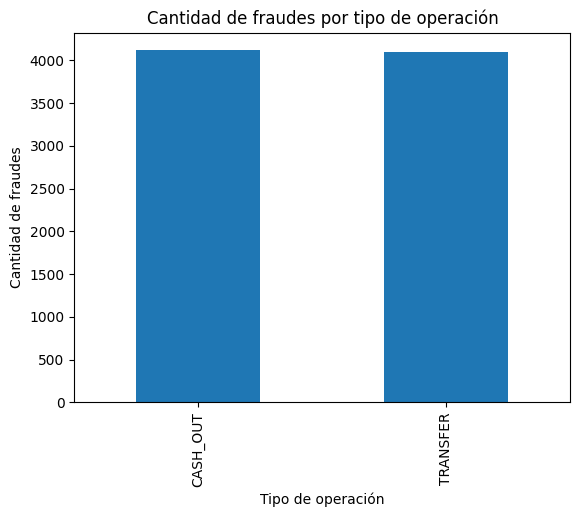

In [ ]:
import matplotlib.pyplot as plt

fraudes_por_tipo = df_completo[df_completo["isFraud"] == 1]["type"].value_counts()

fraudes_por_tipo.plot(kind="bar")

plt.title("Cantidad de fraudes por tipo de operación")
plt.xlabel("Tipo de operación")
plt.ylabel("Cantidad de fraudes")
plt.show()


**Gráfico 2 — Tasa de fraude por tipo.** TRANSFER registra aproximadamente 0,77 % de fraude y CASH_OUT 0,18 %. La tasa permite comparar el riesgo relativo aun cuando los volúmenes de operaciones sean diferentes.


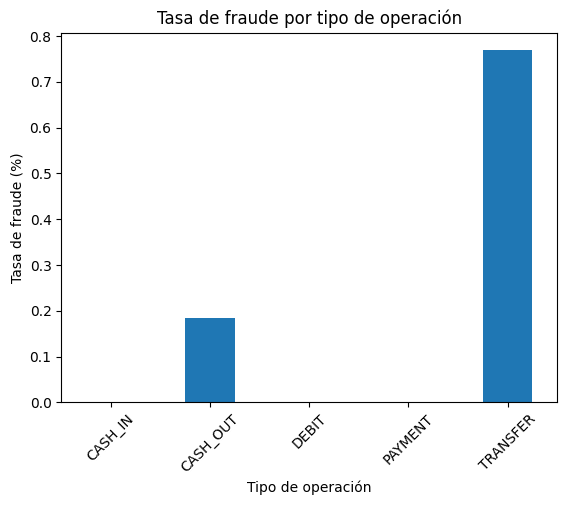

In [ ]:
import matplotlib.pyplot as plt

tabla_fraudes["Tasa_Fraude"].plot(kind="bar")

plt.title("Tasa de fraude por tipo de operación")
plt.xlabel("Tipo de operación")
plt.ylabel("Tasa de fraude (%)")
plt.xticks(rotation=45)
plt.show()


## 4. Evaluación de la regla de alerta

La variable `isFlaggedFraud` identifica 16 operaciones y todas son fraudulentas, pero deja sin marcar 8.197 fraudes. En este conjunto simulado, la regla tiene precisión del 100 % y sensibilidad de aproximadamente 0,19 %; por sí sola es insuficiente.


In [ ]:
print(df_completo["isFlaggedFraud"].value_counts())

isFlaggedFraud
0    6362604
1         16
Name: count, dtype: int64


In [ ]:
tabla_alertas = pd.crosstab(
    df_completo["isFraud"],
    df_completo["isFlaggedFraud"]
)

print(tabla_alertas)

isFlaggedFraud        0   1
isFraud                    
0               6354407   0
1                  8197  16


In [ ]:
fraudes_detectados = tabla_alertas.loc[1, 1]
fraudes_no_detectados = tabla_alertas.loc[1, 0]
falsas_alertas = tabla_alertas.loc[0, 1]

recall = fraudes_detectados / (fraudes_detectados + fraudes_no_detectados) * 100

precision = fraudes_detectados / (fraudes_detectados + falsas_alertas) * 100

print("Sensibilidad:", round(recall, 2), "%")
print("Precisión:", round(precision, 2), "%")

Sensibilidad: 0.19 %
Precisión: 100.0 %


In [ ]:
print("Primer intervalo:", df_completo["step"].min())
print("Último intervalo:", df_completo["step"].max())
print("Cantidad de intervalos:", df_completo["step"].nunique())

Primer intervalo: 1
Último intervalo: 743
Cantidad de intervalos: 743


**Gráfico 3 — Evolución diaria del fraude.** Los días se calculan a partir de `step`, una secuencia de horas simuladas. Se observan variaciones en la cantidad diaria de casos; no deben interpretarse como fechas reales.


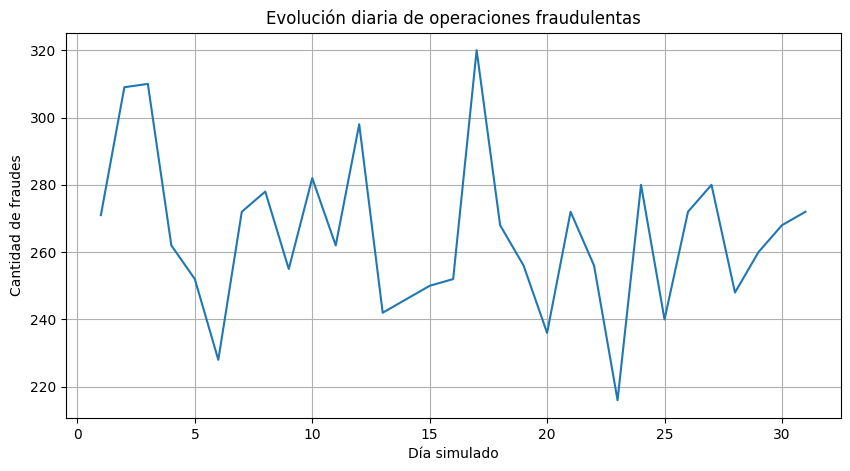

In [ ]:
df_completo["dia"] = ((df_completo["step"] - 1) // 24) + 1

fraudes_por_dia = df_completo[df_completo["isFraud"] == 1].groupby("dia").size()

fraudes_por_dia.plot(kind="line", figsize=(10, 5))

plt.title("Evolución diaria de operaciones fraudulentas")
plt.xlabel("Día simulado")
plt.ylabel("Cantidad de fraudes")
plt.grid(True)
plt.show()


**Gráfico 4 — Tasa de fraude diaria.** Complementa el conteo de casos con la proporción de fraude sobre el total de operaciones de cada día. Los valores extremos requieren considerar el tamaño de la muestra diaria.


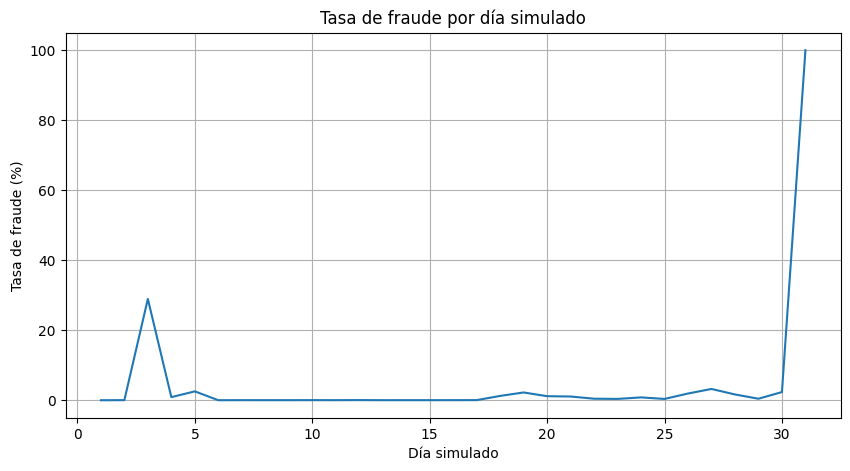

In [ ]:
tasa_diaria = df_completo.groupby("dia")["isFraud"].mean() * 100

tasa_diaria.plot(kind="line", figsize=(10, 5))

plt.title("Tasa de fraude por día simulado")
plt.xlabel("Día simulado")
plt.ylabel("Tasa de fraude (%)")
plt.grid(True)
plt.show()

In [ ]:
resumen_diario = df_completo.groupby("dia").agg(
    operaciones_totales=("isFraud", "count"),
    fraudes=("isFraud", "sum")
)

resumen_diario["tasa_fraude"] = (
    resumen_diario["fraudes"] / resumen_diario["operaciones_totales"] * 100
)

print(resumen_diario.loc[[3, 17, 23, 31]])

     operaciones_totales  fraudes  tasa_fraude
dia                                           
3                   1070      310    28.971963
17                425766      320     0.075159
23                 51012      216     0.423430
31                   272      272   100.000000


**Gráfico 5 — Volumen diario de operaciones.** Permite contextualizar los cambios en cantidad de fraudes: una variación en el volumen total puede afectar los conteos sin implicar necesariamente un aumento proporcional del riesgo.


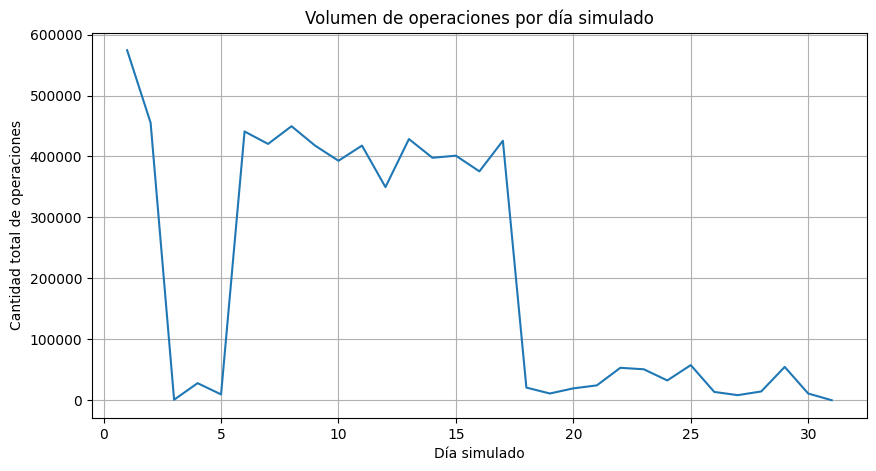

In [ ]:
resumen_diario["operaciones_totales"].plot(
    kind="line",
    figsize=(10, 5)
)

plt.title("Volumen de operaciones por día simulado")
plt.xlabel("Día simulado")
plt.ylabel("Cantidad total de operaciones")
plt.grid(True)
plt.show()


In [ ]:
memoria_mb = df_completo.memory_usage(deep=True).sum() / (1024 ** 2)

print("Memoria utilizada por el dataset:", round(memoria_mb, 2), "MB")

Memoria utilizada por el dataset: 1501.11 MB


In [ ]:
print(df_completo.dtypes)

step                int64
type               object
amount            float64
nameOrig           object
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest           object
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dia                 int64
dtype: object


## 5. Valores atípicos y variables temporales

Los valores atípicos se examinan con el rango intercuartílico (IQR), sin eliminarlos automáticamente porque pueden aportar información sobre fraude.


In [ ]:
print(df_completo["amount"].describe())

count    6.362620e+06
mean     1.798619e+05
std      6.038582e+05
min      0.000000e+00
25%      1.338957e+04
50%      7.487194e+04
75%      2.087215e+05
max      9.244552e+07
Name: amount, dtype: float64


In [ ]:
Q1 = df_completo["amount"].quantile(0.25)
Q3 = df_completo["amount"].quantile(0.75)

IQR = Q3 - Q1

limite_superior = Q3 + 1.5 * IQR

outliers = df_completo[df_completo["amount"] > limite_superior]

print("Límite superior:", round(limite_superior, 2))
print("Cantidad de outliers:", len(outliers))
print("Porcentaje de outliers:", round(len(outliers) / len(df_completo) * 100, 2), "%")

Límite superior: 501719.34
Cantidad de outliers: 338078
Porcentaje de outliers: 5.31 %


In [ ]:
print("Outliers legítimos:", (outliers["isFraud"] == 0).sum())

print("Outliers fraudulentos:", (outliers["isFraud"] == 1).sum())

print("Porcentaje de fraudes que son outliers:",
      round((outliers["isFraud"] == 1).sum() / 8213 * 100, 2), "%")


Outliers legítimos: 334224
Outliers fraudulentos: 3854
Porcentaje de fraudes que son outliers: 46.93 %


In [ ]:
df_completo["hora"] = (df_completo["step"] - 1) % 24

print(df_completo[["step", "dia", "hora"]].head(10))

   step  dia  hora
0     1    1     0
1     1    1     0
2     1    1     0
3     1    1     0
4     1    1     0
5     1    1     0
6     1    1     0
7     1    1     0
8     1    1     0
9     1    1     0


In [ ]:
print("Días simulados:", df_completo["dia"].min(), "a", df_completo["dia"].max())

print("Horas simuladas:", df_completo["hora"].min(), "a", df_completo["hora"].max())

print("Categorías:", df_completo["type"].unique())


Días simulados: 1 a 31
Horas simuladas: 0 a 23
Categorías: ['PAYMENT' 'TRANSFER' 'CASH_OUT' 'DEBIT' 'CASH_IN']


In [ ]:
import seaborn as sns

print("Seaborn está listo para usar")

Seaborn está listo para usar


## 6. Visualizaciones complementarias con Seaborn

Se comparan importes promedio, tasas por categoría, importes fraudulentos, evolución temporal y resultados de la regla de alerta. Son visualizaciones complementarias a las cinco anteriores.


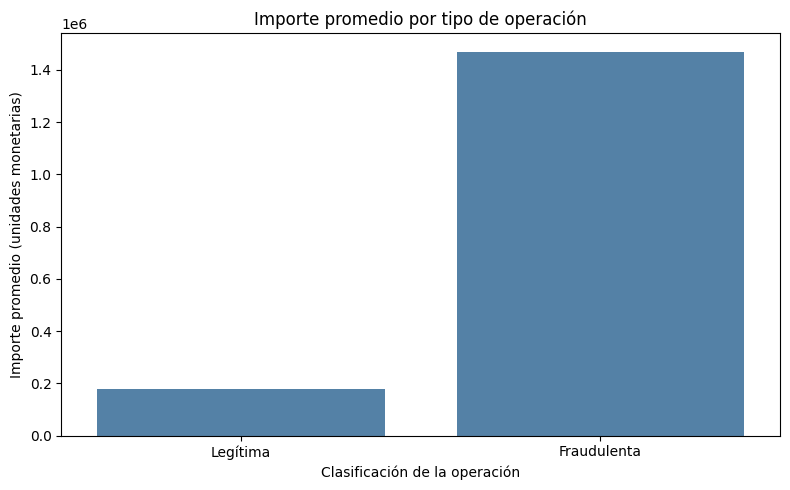

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

promedios = df_completo.groupby("isFraud")["amount"].mean().reset_index()

promedios["Tipo"] = promedios["isFraud"].map({
    0: "Legítima",
    1: "Fraudulenta"
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=promedios,
    x="Tipo",
    y="amount",
    color="steelblue"
)

plt.title("Importe promedio por tipo de operación")
plt.xlabel("Clasificación de la operación")
plt.ylabel("Importe promedio (unidades monetarias)")
plt.tight_layout()
plt.show()

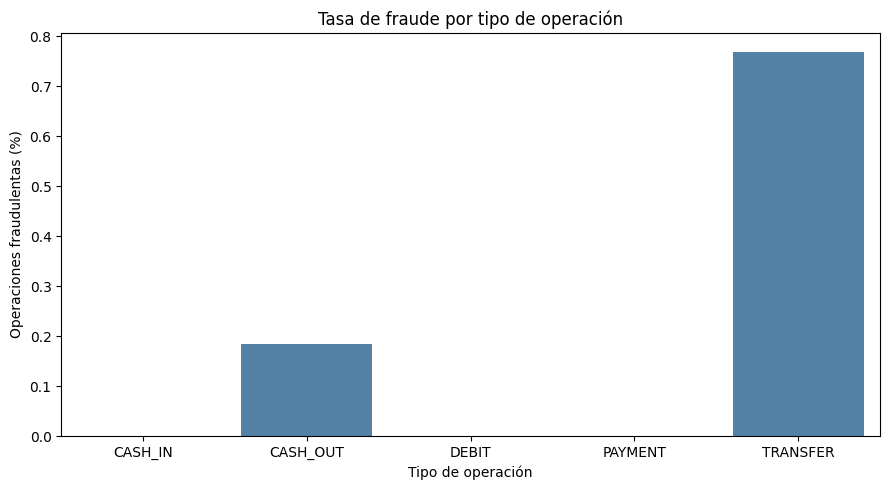

In [ ]:

tasas = (
    df_completo.groupby("type")["isFraud"]
    .mean()
    .mul(100)
    .reset_index()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=tasas,
    x="type",
    y="isFraud",
    color="steelblue"
)

plt.title("Tasa de fraude por tipo de operación")
plt.xlabel("Tipo de operación")
plt.ylabel("Operaciones fraudulentas (%)")
plt.tight_layout()
plt.show()


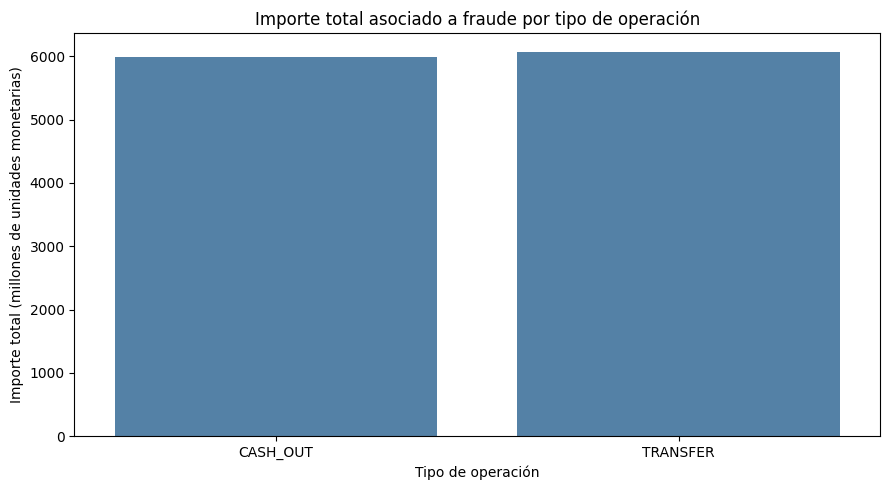

In [ ]:

montos_fraude = (
    df_completo[df_completo["isFraud"] == 1]
    .groupby("type")["amount"]
    .sum()
    .div(1_000_000)
    .reset_index()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=montos_fraude,
    x="type",
    y="amount",
    color="steelblue"
)

plt.title("Importe total asociado a fraude por tipo de operación")
plt.xlabel("Tipo de operación")
plt.ylabel("Importe total (millones de unidades monetarias)")
plt.tight_layout()
plt.show()


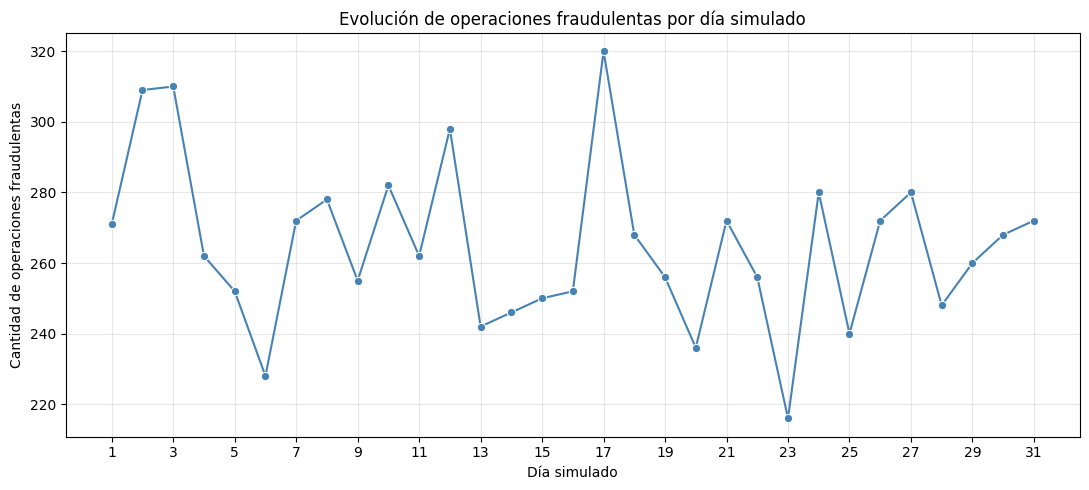

In [ ]:
fraudes_por_dia = (
    df_completo.groupby("dia")["isFraud"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=fraudes_por_dia,
    x="dia",
    y="isFraud",
    marker="o",
    color="steelblue"
)

plt.title("Evolución de operaciones fraudulentas por día simulado")
plt.xlabel("Día simulado")
plt.ylabel("Cantidad de operaciones fraudulentas")
plt.xticks(range(1, 32, 2))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


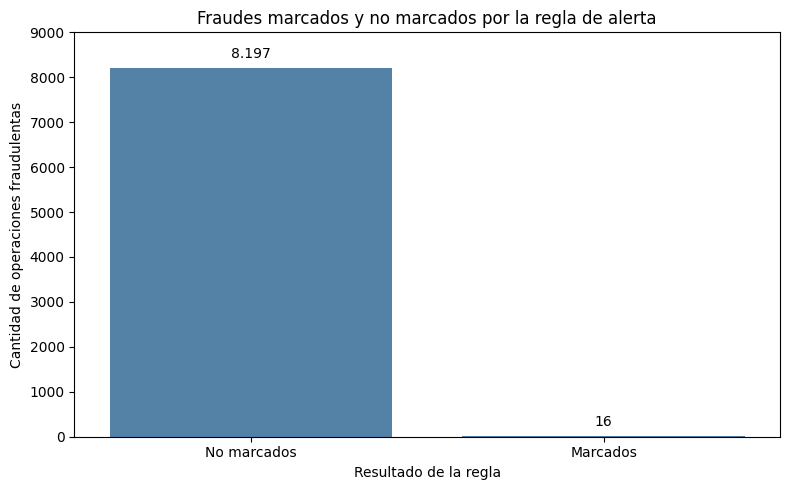

In [ ]:

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=alertas,
    x="Estado",
    y="Cantidad",
    color="steelblue"
)

for barra in ax.patches:
    altura = barra.get_height()
    ax.annotate(
        f"{int(altura):,}".replace(",", "."),
        (barra.get_x() + barra.get_width() / 2, altura),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.title("Fraudes marcados y no marcados por la regla de alerta")
plt.xlabel("Resultado de la regla")
plt.ylabel("Cantidad de operaciones fraudulentas")
plt.ylim(0, 9000)
plt.tight_layout()
plt.show()



## 7. Preparación y validación de datos para Power BI

Se genera una tabla agregada para facilitar la construcción del dashboard. Se comprueba que la suma de operaciones y fraudes coincida con el dataset original.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

archivo = "/content/drive/MyDrive/Proyecto_Fraude_Bancario./PS_20174392719_1491204439457_log.csv"

df_completo = pd.read_csv(archivo)

print("Filas:", len(df_completo))
print("Columnas:", df_completo.columns.tolist())

Filas: 6362620
Columnas: ['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']


In [ ]:
df_completo["dia"] = ((df_completo["step"] - 1) // 24) + 1
df_completo["hora"] = (df_completo["step"] - 1) % 24

print(df_completo[["step", "dia", "hora"]].head(10))
print("Días:", df_completo["dia"].min(), "a", df_completo["dia"].max())
print("Horas:", df_completo["hora"].min(), "a", df_completo["hora"].max())

   step  dia  hora
0     1    1     0
1     1    1     0
2     1    1     0
3     1    1     0
4     1    1     0
5     1    1     0
6     1    1     0
7     1    1     0
8     1    1     0
9     1    1     0
Días: 1 a 31
Horas: 0 a 23


In [ ]:
datos_powerbi = (
    df_completo.groupby(
        ["dia", "hora", "type", "isFraud", "isFlaggedFraud"],
        as_index=False
    )
    .agg(
        cantidad_operaciones=("amount", "size"),
        importe_total=("amount", "sum")
    )
)

print("Filas originales:", len(df_completo))
print("Filas resumidas:", len(datos_powerbi))
print(datos_powerbi.head())

Filas originales: 6362620
Filas resumidas: 3583
   dia  hora      type  isFraud  isFlaggedFraud  cantidad_operaciones  \
0    1     0   CASH_IN        0               0                   527   
1    1     0  CASH_OUT        0               0                   379   
2    1     0  CASH_OUT        1               0                     9   
3    1     0     DEBIT        0               0                   148   
4    1     0   PAYMENT        0               0                  1369   

   importe_total  
0    85500789.61  
1    64485230.45  
2     2144545.49  
3      663632.33  
4     8337616.69  


In [ ]:
print("VALIDACIÓN DE OPERACIONES")
print("Original:", len(df_completo))
print("Resumido:", datos_powerbi["cantidad_operaciones"].sum())

print("\nVALIDACIÓN DE FRAUDES")
print("Original:", df_completo["isFraud"].sum())
print(
    "Resumido:",
    datos_powerbi.loc[
        datos_powerbi["isFraud"] == 1,
        "cantidad_operaciones"
    ].sum()
)

print("\nVALIDACIÓN DE IMPORTES")
print("Original:", round(df_completo["amount"].sum(), 2))
print("Resumido:", round(datos_powerbi["importe_total"].sum(), 2))

VALIDACIÓN DE OPERACIONES
Original: 6362620
Resumido: 6362620

VALIDACIÓN DE FRAUDES
Original: 8213
Resumido: 8213

VALIDACIÓN DE IMPORTES
Original: 1144392944759.77
Resumido: 1144392944759.77


In [ ]:
ruta_salida = "/content/drive/MyDrive/Proyecto_Fraude_Bancario./datos_resumidos_powerbi.csv"

datos_powerbi.to_csv(ruta_salida, index=False)

print("Archivo guardado correctamente en:")
print(ruta_salida)


Archivo guardado correctamente en:
/content/drive/MyDrive/Proyecto_Fraude_Bancario./datos_resumidos_powerbi.csv


## Conclusiones

De 6.362.620 transacciones simuladas, 8.213 (0,13 %) están etiquetadas como fraudulentas. Los fraudes se concentran en CASH_OUT y TRANSFER; aunque el número de casos es similar, la tasa de fraude es mayor en TRANSFER. La regla `isFlaggedFraud` detecta una proporción muy pequeña de los casos, lo que sugiere complementar las alertas con otros indicadores. Los resultados son exploratorios y no deben extrapolarse directamente a operaciones bancarias reales.

**Fuente:** [PaySim en Kaggle](https://www.kaggle.com/datasets/ealaxi/paysim1).
